In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.layers import Embedding, SimpleRNN, Dense, Dropout,Input
from tensorflow.keras.models import Model
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.datasets import imdb


# LOAD DATASET

In [2]:
df=pd.read_csv(r'c:\Users\HP\Downloads\archive (1)\IMDB Dataset.csv')

In [3]:
df.head()

,review,sentiment
0,One of the other reviewers has mentioned that ...,positive
1,A wonderful little production. <br /><br />The...,positive
2,I thought this was a wonderful way to spend ti...,positive
3,Basically there's a family where a little boy ...,negative
4,"Petter Mattei's ""Love in the Time of Money"" is...",positive


In [4]:
print("Dataset Shape: ",df.shape)

Dataset Shape:  (50000, 2)


In [5]:
print(df.columns)

Index(['review', 'sentiment'], dtype='str')


In [6]:
df['sentiment'].value_counts()

sentiment
positive    25000
negative    25000
Name: count, dtype: int64

In [7]:
df['sentiment']=df['sentiment'].map({
    'positive':1,
    'negative':0
})

In [8]:
df['sentiment']

0        1
1        1
2        1
3        0
4        1
        ..
49995    1
49996    0
49997    0
49998    0
49999    0
Name: sentiment, Length: 50000, dtype: int64

In [9]:
print(df.head())

                                              review  sentiment
0  One of the other reviewers has mentioned that ...          1
1  A wonderful little production. <br /><br />The...          1
2  I thought this was a wonderful way to spend ti...          1
3  Basically there's a family where a little boy ...          0
4  Petter Mattei's "Love in the Time of Money" is...          1


In [10]:
import re
import string

In [11]:
def clean_text(text):
    # Convert to string
    text = str(text)

    # Convert to lowercase
    text = text.lower()

    # Remove HTML tags
    text = re.sub(r'<.*?>', ' ', text)

    # Remove URLs
    text = re.sub(r'http\S+|www\S+', ' ', text)

    # Remove mentions and hashtags symbols
    text = re.sub(r'@\w+|#\w+', ' ', text)

    # Remove punctuation
    text = text.translate(str.maketrans('', '', string.punctuation))

    # Remove numbers
    text = re.sub(r'\d+', ' ', text)

    # Remove extra whitespace
    text = re.sub(r'\s+', ' ', text).strip()

    return text

In [12]:
df['clean_review'] = df['review'].apply(clean_text)

In [13]:
df = df.dropna(subset=['clean_review', 'sentiment'])

In [14]:
X = df['clean_review'].to_numpy()
y = df['sentiment'].to_numpy()


print(df[['review', 'clean_review', 'sentiment']].head())

print("X shape:", X.shape)
print("y shape:", y.shape)

                                              review  \
0  One of the other reviewers has mentioned that ...   
1  A wonderful little production. <br /><br />The...   
2  I thought this was a wonderful way to spend ti...   
3  Basically there's a family where a little boy ...   
4  Petter Mattei's "Love in the Time of Money" is...   

                                        clean_review  sentiment  
0  one of the other reviewers has mentioned that ...          1  
1  a wonderful little production the filming tech...          1  
2  i thought this was a wonderful way to spend ti...          1  
3  basically theres a family where a little boy j...          0  
4  petter matteis love in the time of money is a ...          1  
X shape: (50000,)
y shape: (50000,)


# Split into training and testing data

In [15]:
from sklearn.model_selection import train_test_split

In [16]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

In [17]:
print("Training reviews:", len(X_train))
print("Testing reviews:", len(X_test))

Training reviews: 40000
Testing reviews: 10000


# Tokenization

In [18]:
vocab_size = 10000

tokenizer = Tokenizer(
    num_words=vocab_size,
    oov_token="<OOV>"
)

tokenizer.fit_on_texts(X_train)

In [19]:
X_train_sequences = tokenizer.texts_to_sequences(X_train)

X_test_sequences = tokenizer.texts_to_sequences(X_test)

In [20]:
print(X_train[0])
print(X_train_sequences[0])

i caught this little gem totally by accident back in or i was at a revival theatre to see two old silly scifi movies the theatre was packed full and with no warning they showed a bunch of scifi short spoofs to get us in the mood most were somewhat amusing but this came on and within seconds the audience was in hysterics the biggest laugh came when they showed princess laia having huge cinnamon buns instead of hair on her head she looks at the camera gives a grim smile and nods that made it even funnier you gotta see chewabacca played by what looks like a muppet it was extremely silly and stupidbut i couldnt stop laughing most of the dialogue was drowned out because of all the laughter also if you know star wars pretty well its even funnierthey deliberately poke fun at some of the dialogue this really works with an audience a definite
[10, 1021, 11, 117, 1442, 441, 32, 1586, 143, 8, 39, 10, 13, 30, 4, 8593, 1622, 6, 64, 107, 170, 652, 881, 91, 2, 1622, 13, 3289, 370, 3, 16, 55, 1748, 34

# Padding

In [21]:
max_length=200

In [22]:
X_train = pad_sequences(
    X_train_sequences,
    maxlen=max_length,
    padding="post",
    truncating="post"
)

In [23]:
X_test = pad_sequences(
    X_test_sequences,
    maxlen=max_length,
    padding="post",
    truncating="post"
)

In [24]:
print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)

print("y_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)

X_train shape: (40000, 200)
X_test shape: (10000, 200)
y_train shape: (40000,)
y_test shape: (10000,)


# TRAIN CNN MODEL

In [25]:
embed_dim=16
rnn_unit=8

In [26]:
input=Input(shape=(max_length,),dtype='int32',name='inp')
x=Embedding(input_dim=vocab_size,output_dim=rnn_unit,mask_zero=True,name="embed")(input)
rnn=SimpleRNN(units=rnn_unit,return_sequences=False,return_state=False,name="rnn_units")
x_last=rnn(x)
output=Dense(1,activation='sigmoid',name='out')(x_last)
model = Model(inputs =input,outputs = output)
model.compile(optimizer='adam',loss = 'binary_crossentropy',metrics=['accuracy'])
model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ inp (InputLayer)    │ (None, 200)       │          0 │ -                 │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embed (Embedding)   │ (None, 200, 8)    │     80,000 │ inp[0][0]         │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ not_equal           │ (None, 200)       │          0 │ inp[0][0]         │
│ (NotEqual)          │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ rnn_units           │ (None, 8)         │        136 │ embed[0][0],      │
│ (SimpleRNN)         │                   │            │ not_equal[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ out (Dense)         │ (None, 1)         │          9 │ rnn_units[0][0]   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 80,145 (313.07 KB)

 Trainable params: 80,145 (313.07 KB)

 Non-trainable params: 0 (0.00 B)

In [27]:
history=model.fit(X_train,y_train,epochs=5,batch_size=64,validation_split=0.2)

Epoch 1/5
500/500 ━━━━━━━━━━━━━━━━━━━━ 20s 38ms/step - accuracy: 0.5263 - loss: 0.6895 - val_accuracy: 0.5408 - val_loss: 0.6828
Epoch 2/5
500/500 ━━━━━━━━━━━━━━━━━━━━ 17s 35ms/step - accuracy: 0.6262 - loss: 0.6496 - val_accuracy: 0.5676 - val_loss: 0.6702
Epoch 3/5
500/500 ━━━━━━━━━━━━━━━━━━━━ 18s 35ms/step - accuracy: 0.7212 - loss: 0.5683 - val_accuracy: 0.7552 - val_loss: 0.5380
Epoch 4/5
500/500 ━━━━━━━━━━━━━━━━━━━━ 19s 38ms/step - accuracy: 0.8536 - loss: 0.3587 - val_accuracy: 0.7962 - val_loss: 0.4660
Epoch 5/5
500/500 ━━━━━━━━━━━━━━━━━━━━ 18s 37ms/step - accuracy: 0.9067 - loss: 0.2489 - val_accuracy: 0.7103 - val_loss: 0.6329


# Evaluate on Test Data

In [28]:
test_loss, test_accuracy = model.evaluate(
    X_test,
    y_test
)

print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy)

313/313 ━━━━━━━━━━━━━━━━━━━━ 4s 11ms/step - accuracy: 0.7140 - loss: 0.6245
Test Loss: 0.6244570016860962
Test Accuracy: 0.7139999866485596


# PLOT TRANING LOSS

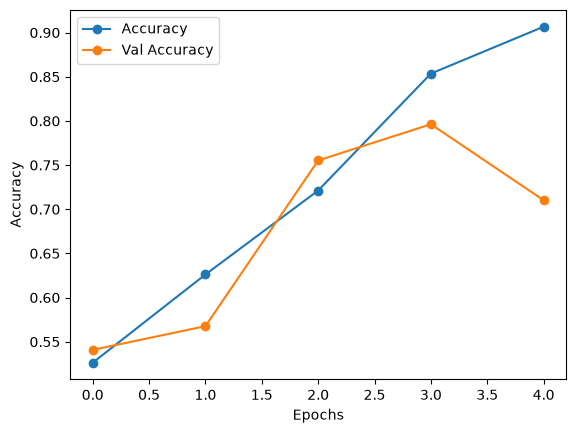

In [29]:
plt.plot(history.history['accuracy'],label="Accuracy",marker='o')
plt.plot(history.history['val_accuracy'],label='Val Accuracy',marker='o')
plt.legend()
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.show()

# PLOT TRANING LOSS

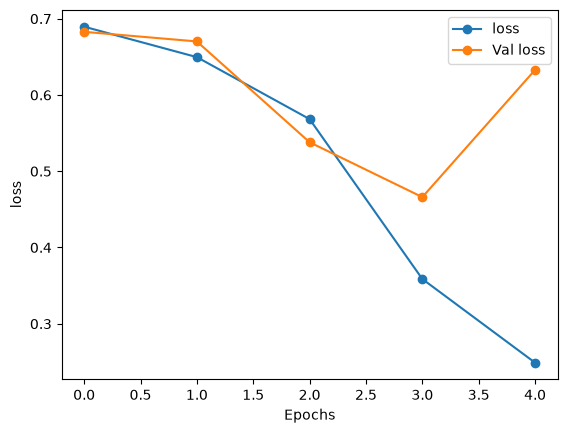

In [30]:
plt.plot(history.history['loss'],label="loss",marker='o')
plt.plot(history.history['val_loss'],label='Val loss',marker='o')
plt.legend()
plt.xlabel("Epochs")
plt.ylabel("loss")
plt.show()

# MAKE PREDICTION

In [31]:
prediction=model.predict(X_test,verbose=0)

In [32]:
y_pred=np.argmax(prediction)

# WRONG PREDICTION

In [33]:
wrong_indices=np.where(y_pred!=y_test)[0]
print("wrong_indices: ",len(wrong_indices))

wrong_indices:  10000


# Predict a New Movie Review

In [34]:
predict_sentiment=(
    "What an amazing movie! The director did a great job creating "
    "an emotional and entertaining story. The performances were "
    "excellent and the music fit perfectly with every scene. "
    "I laughed, I felt emotional, and I enjoyed every minute of it."
)

In [35]:
review_sequence = tokenizer.texts_to_sequences(predict_sentiment)

In [36]:
review_padded = pad_sequences(
    review_sequence,
    maxlen=max_length,
    padding="post",
    truncating="post"
)

In [37]:
prediction = model.predict(review_padded)

print("Prediction probability:", prediction[0][0])

8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step
Prediction probability: 0.2163039


In [38]:
if prediction[0][0] >= 0.5:
    print("Sentiment: Positive")
else:
    print("Sentiment: Negative")

Sentiment: Negative


In [39]:
model.save(
    "IMDB_Simple_RNN.keras"
)

In [40]:
def predict_sentiment(text):

    sequence = tokenizer.texts_to_sequences([text])

    padded = pad_sequences(
        sequence,
        maxlen=max_length,
        padding="post",
        truncating="post"
    )

    prediction = model.predict(
        padded,
        verbose=0
    )[0][0]


    if prediction >= 0.5:

        sentiment = "Positive"
        confidence = prediction * 100

    else:

        sentiment = "Negative"
        confidence = (1 - prediction) * 100


    print("\nReview:", text)

    print(
        "Prediction:",
        prediction
    )

    print(
        "Sentiment:",
        sentiment
    )

    print(
        "Confidence:",
        f"{confidence:.2f}%"
    )


# ============================================
# 7. Test Predictions
# ============================================

predict_sentiment(
    "This was an absolutely wonderful movie. "
    "The story was interesting, the actors performed brilliantly, "
    "and every scene was enjoyable. I loved the characters and "
    "the ending was excellent. I would definitely recommend this movie."
)

predict_sentiment(
    "I really enjoyed watching this film from beginning to end. "
    "The acting was fantastic and the story was very engaging. "
    "The characters were realistic and the cinematography was beautiful. "
    "This is one of the best movies I have watched in a long time."
)

predict_sentiment(
    "What an amazing movie! The director did a great job creating "
    "an emotional and entertaining story. The performances were "
    "excellent and the music fit perfectly with every scene. "
    "I laughed, I felt emotional, and I enjoyed every minute of it."
)
predict_sentiment(
    "This movie was extremely disappointing. "
    "The story was boring and predictable, the acting was poor, "
    "and the characters were not interesting at all. "
    "I struggled to finish the movie and would not recommend it."
)
predict_sentiment(
    "I really disliked this film. The plot was confusing and "
    "the characters had no depth. The acting felt unnatural "
    "and many scenes were unnecessarily long. "
    "Overall, this was a boring movie and a complete waste of time."
)
predict_sentiment(
    "I expected this movie to be much better, but unfortunately "
    "it was terrible. The story moved very slowly and the dialogue "
    "was poorly written. The actors did not perform well and "
    "the ending was extremely disappointing."
)
predict_sentiment(
    "The movie started very well and the acting was excellent, "
    "but the story became boring near the end."
)
predict_sentiment(
    "I liked the characters and the music, although the story "
    "was sometimes slow and predictable."
)
predict_sentiment(
    "The movie was not perfect, but overall I enjoyed watching it "
    "and I would recommend it to my friends."
)


Review: This was an absolutely wonderful movie. The story was interesting, the actors performed brilliantly, and every scene was enjoyable. I loved the characters and the ending was excellent. I would definitely recommend this movie.
Prediction: 0.9475172
Sentiment: Positive
Confidence: 94.75%

Review: I really enjoyed watching this film from beginning to end. The acting was fantastic and the story was very engaging. The characters were realistic and the cinematography was beautiful. This is one of the best movies I have watched in a long time.
Prediction: 0.9459226
Sentiment: Positive
Confidence: 94.59%

Review: What an amazing movie! The director did a great job creating an emotional and entertaining story. The performances were excellent and the music fit perfectly with every scene. I laughed, I felt emotional, and I enjoyed every minute of it.
Prediction: 0.8675064
Sentiment: Positive
Confidence: 86.75%

Review: This movie was extremely disappointing. The story was boring and pred

In [41]:
import pickle

with open("imdb_tokenizer.pkl", "wb") as file:
    pickle.dump(tokenizer, file)

print("Tokenizer saved successfully!")

Tokenizer saved successfully!


In [42]:
from tensorflow.keras.models import load_model
import pickle

model = load_model( "IMDB_Simple_RNN.keras")

with open("imdb_tokenizer.pkl", "rb") as file:
    tokenizer = pickle.load(file)

print("Model and tokenizer loaded successfully!")

Model and tokenizer loaded successfully!


In [43]:
from tensorflow.keras.preprocessing.sequence import pad_sequences

def predict_sentiment(review):

    # Text → sequence
    sequence = tokenizer.texts_to_sequences([review])

    # Padding
    padded = pad_sequences(
        sequence,
        maxlen=200,
        padding="post",
        truncating="post"
    )

    # Prediction
    prediction = model.predict(padded, verbose=0)[0][0]

    if prediction >= 0.5:
        sentiment = "Positive"
    else:
        sentiment = "Negative"

    print("Review:", review)
    print("Prediction Score:", prediction)
    print("Sentiment:", sentiment)

    return sentiment

In [44]:
predict_sentiment(
    "This movie was absolutely amazing. I really enjoyed it!"
)

Review: This movie was absolutely amazing. I really enjoyed it!
Prediction Score: 0.89854443
Sentiment: Positive


'Positive'

In [45]:
predict_sentiment(
    "This movie was terrible and extremely boring. I hated it."
)

Review: This movie was terrible and extremely boring. I hated it.
Prediction Score: 0.06813332
Sentiment: Negative


'Negative'

In [2]:
import sys
import tensorflow as tf

print(sys.executable)
print(tf.__version__)
print(tf.__file__)

c:\Users\HP\OneDrive\Desktop\DEEP LEARNING\tf_env\Scripts\python.exe
2.21.0
c:\Users\HP\OneDrive\Desktop\DEEP LEARNING\tf_env\Lib\site-packages\tensorflow\__init__.py
